# Prediction of Effective Temperature and Rotational Velocity in Massive Stars using Machine Learning
---
**Objectives:**  
* Preprocess data for Machine Learning models
* Use simple Machine Learning models to estimate stellar parameters
* Learn how to optimize Machine Learning models.

**Data:**  
* Subset of Be-star spectra generated by PhD candidate Daniela Turis (IFA-UV) using the ZPEKTR code.

---
### Notebook Summary
When using Machine learning, this problem is addressed as a **multi-output regression** task.

In this activity:  
1. Exploratory Data Analysis (EDA)
2. Data preprocessing 
3. Model training and evaluation
4. Model optimization
5. Testing with a real spectrum

## Python Libraries
*tools already implemented that we can use*
***

In [ ]:
#System libraries
import os
import sys
import time

#Data managment
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gdown



#Machine learning 
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor


#Model evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score



### Custom functions
---


In [15]:
def plot_spectrum(wavelengths, flux, title="Spectrum", figsize=(10,5)):
    """
    Plot a stellar spectrum using an astrophysics-style dark theme.
    """

    #Create a figure where to plot
    plt.style.use("dark_background")
    plt.figure(figsize=figsize)

    #Draw the plot 
    plt.plot(wavelengths, flux, color="cyan", linewidth=1.8)

    #Visual configs
    plt.title(title, fontsize=14, color="white")
    plt.xlabel("Wavelength [Å]", fontsize=12, color="white")
    plt.ylabel("Flux", fontsize=12, color="white")
    plt.grid(color="gray", alpha=0.3, linestyle="--")

    #Show the figure
    plt.tight_layout()
    plt.show()


def plot_results(y_test, y_pred, model_name):
    """
    Show error metrics: MSE, MAE, R^2
    Plot predictions v/s real values

    """
    plt.style.use("seaborn-v0_8-whitegrid")
    targets = ["T_eff", "v sin i"]

    #Metrics report
    for i, target in enumerate(targets):
        print(f"{target} – {model_name}")
        print(f"  MSE: {mean_squared_error(y_test.values[:, i], y_pred[:, i]):.2f}")
        print(f"  MAE: {mean_absolute_error(y_test.values[:, i], y_pred[:, i]):.2f}")
        print(f"  R²:  {r2_score(y_test.values[:, i], y_pred[:, i]):.3f}\n")

    #Scatter plot: model predictions v/s real
    plt.figure(figsize=(12, 5)) 
    for i, target in enumerate(targets):
        plt.subplot(1, 2, i+1)
        sns.scatterplot(x=y_test.values[:, i], y=y_pred[:, i], alpha=0.4)
        plt.plot(
            [y_test.values[:, i].min(), y_test.values[:, i].max()],
            [y_test.values[:, i].min(), y_test.values[:, i].max()],
            'r--'
        )
        plt.xlabel(f"True {target}")
        plt.ylabel(f"Predicted {target}")
        plt.title(f"{target} – {model_name}")
        plt.grid(True)

    plt.tight_layout()
    plt.show()


## 1. Exploratory Data Analysis (EDA)
---

#### Data download

In [ ]:
#Dataset provided by PhD (c) Daniela Turis, IFA-UV.

#Check if you are running in Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    #Download using gdown
    import gdown
    !gdown https://drive.google.com/uc?id=1m_GajQqDRcKrH8_ExG_0Yp_sQ4MrhZbN
    data=pd.read_csv("df_ZPEKTR_limb_lineal.csv")

    #Also download figures of the jupyter
    if not os.path.exists("Figures"):
        !gdown --folder https://drive.google.com/drive/folders/11M7KYcIFg1-6saGYJhbJwCrLYT7kbE2A

else:
    #Search file in local distk
    file_path = "Data/ML/df_ZPEKTR_limb_lineal.csv"
    if os.path.exists(file_path):
        print("File loaded:", file_path)
        data=pd.read_csv(file_path)

    else:
        print("File not found. Please download it or check the file path.")

File loaded: Data/ML/df_ZPEKTR_limb_lineal.csv


#### Inspect the data
We loaded the dataset using `read_csv` from the library `pandas` which generated a `DataFrame`, similar to a table. We can inspect the data:
* `data.head()`-> prints the first 5 rows of the DataFrame
* `data.columns` -> returns all the column names
* `data.info()` -> prints a summary of the DataFrame
* `data.describe()` -> prints a statistical summary of the DataFrame
* `data["vsini"]` -> Access to a column
* ....


In [17]:
data.head()

,4460.1,4460.2,4460.3,4460.4,4460.5,4460.6,4460.7,4460.8,4460.9,4461.0,...,vsini,M/M⊙,R/R⊙,V/Vc,L*,Ω/Ωc,Tpole,Teq,gpole,geq
0,0.996583,0.996529,0.996452,0.996362,0.996264,0.996160,0.996052,0.995942,0.995830,0.995717,...,228.0,15.0,5.79,0.75,4.105,0.912,28000.0,23690.0,4.20,4.02
1,0.996234,0.996208,0.996180,0.996141,0.996108,0.996074,0.996027,0.995962,0.995851,0.995678,...,309.0,17.0,5.75,0.77,4.230,0.928,30000.0,25014.0,4.25,4.06
2,0.997128,0.996958,0.996770,0.996573,0.996368,0.996163,0.995957,0.995746,0.995530,0.995321,...,254.0,10.0,8.42,0.65,3.857,0.836,19000.0,16859.0,3.63,3.50
3,0.993683,0.993541,0.993413,0.993277,0.993126,0.992986,0.992836,0.992683,0.992531,0.992366,...,351.0,12.0,5.31,0.68,3.351,0.860,18000.0,15772.0,4.12,3.98
4,0.995026,0.994887,0.994749,0.994607,0.994464,0.994324,0.994183,0.994040,0.993885,0.993727,...,310.0,12.0,6.35,0.65,3.778,0.842,21000.0,18578.0,3.96,3.83


In [18]:
data.describe()

,4460.1,4460.2,4460.3,4460.4,4460.5,4460.6,4460.7,4460.8,4460.9,4461.0,...,vsini,M/M⊙,R/R⊙,V/Vc,L*,Ω/Ωc,Tpole,Teq,gpole,geq
count,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,...,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000,10691.000000
mean,0.995906,0.995780,0.995650,0.995517,0.995380,0.995241,0.995099,0.994954,0.994804,0.994656,...,246.732579,13.175942,7.500384,0.687894,3.873786,0.861596,21716.443738,18749.321672,3.887326,3.735335
std,0.001478,0.001559,0.001638,0.001714,0.001784,0.001848,0.001905,0.001956,0.002004,0.002034,...,85.483090,3.307163,1.863544,0.080427,0.360840,0.056669,4679.880000,3652.135035,0.277166,0.257807
min,0.987578,0.987139,0.986615,0.986055,0.985369,0.984751,0.984198,0.983735,0.983387,0.982855,...,61.000000,4.000000,5.250000,0.520000,2.568000,0.712000,10500.000000,9068.000000,3.230000,3.080000
25%,0.995435,0.995299,0.995164,0.995027,0.994883,0.994731,0.994574,0.994413,0.994234,0.994044,...,180.000000,12.000000,5.990000,0.640000,3.727000,0.827000,19000.000000,16529.000000,3.710000,3.580000
50%,0.996152,0.996061,0.995964,0.995857,0.995748,0.995629,0.995503,0.995368,0.995224,0.995072,...,265.000000,14.000000,7.400000,0.680000,3.994000,0.860000,21000.000000,18802.000000,3.890000,3.750000
75%,0.996743,0.996661,0.996578,0.996489,0.996399,0.996302,0.996208,0.996106,0.995998,0.995888,...,312.000000,16.000000,8.490000,0.710000,4.115000,0.887000,25000.000000,21239.000000,4.120000,3.950000
max,0.998244,0.998187,0.998145,0.998120,0.998074,0.997998,0.997920,0.997869,0.997690,0.997525,...,444.000000,18.000000,13.620000,0.930000,4.336000,0.993000,30000.000000,27248.000000,4.280000,4.170000


In [19]:
vsini = data["vsini"]
print("Mean: ", vsini.mean())
print("Std: ", vsini.std())

Mean:  246.732578804602
Std:  85.48309010774473


In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10691 entries, 0 to 10690
Columns: 188 entries, 4460.1 to geq
dtypes: float64(188)
memory usage: 15.3 MB


From the EDA, we can see that the data contains 10,691 spectra, each described by 188 columns. The first columns contain the wavelength and its corresponding flux values, and the last columns are their associated stellar parameters.

When using unknow datasets further inspections can be done:
* Data visualization using dimension reduction techniques (PCA, tSNE, UMAP)
* Verify if data containes `NaN`values 
* Outlier and anomalies detection
* ...

## 2. Data preprocessing
---
In machine lerning, it is common to create a matrix $X$ for the input data and a matrix $y$ for the outputs. 

* $X$ will contain the n=10,691 spectra
* $y$ will contain the labels of each spectra. In this case just `Teff`and `vsini`

In [21]:

X = data.iloc[:, 0:170] # Select all the rows, and the columns 0 to 169
y = data[["<Teff>", "vsini"]]# Select all the rows, and the columns named "<Teff>" and "vsini"

wavelengths = np.array(data.columns)[0:170].astype(float) #Obtain the wavelengths

#### Example of spectrum ploting

*Use whichever plot you prefer*

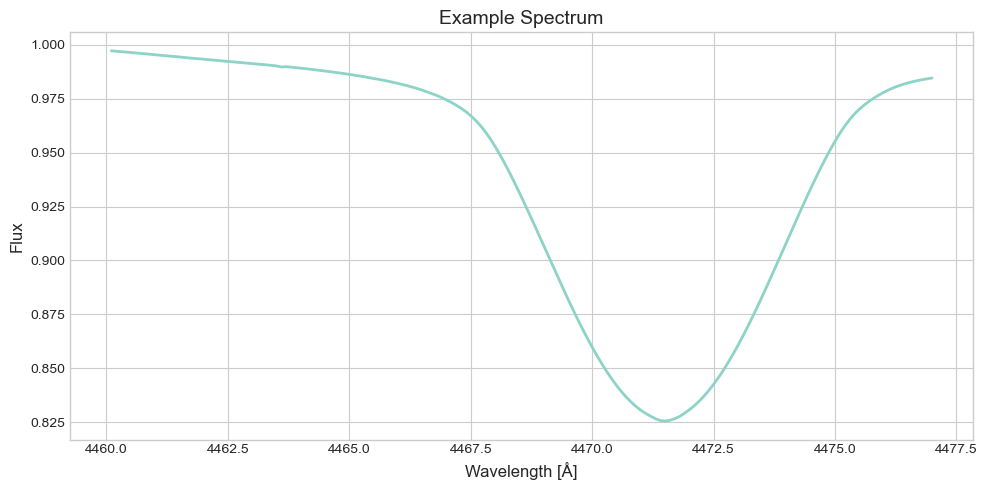

In [22]:
flux_values = X.iloc[2, :] #acces to all the columns (wavelength) of the second index spectra

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(10,5))

plt.plot(wavelengths, flux_values, linewidth=2)

plt.title("Example Spectrum", fontsize=14)
plt.xlabel("Wavelength [Å]", fontsize=12)
plt.ylabel("Flux", fontsize=12)

plt.tight_layout()
plt.show()

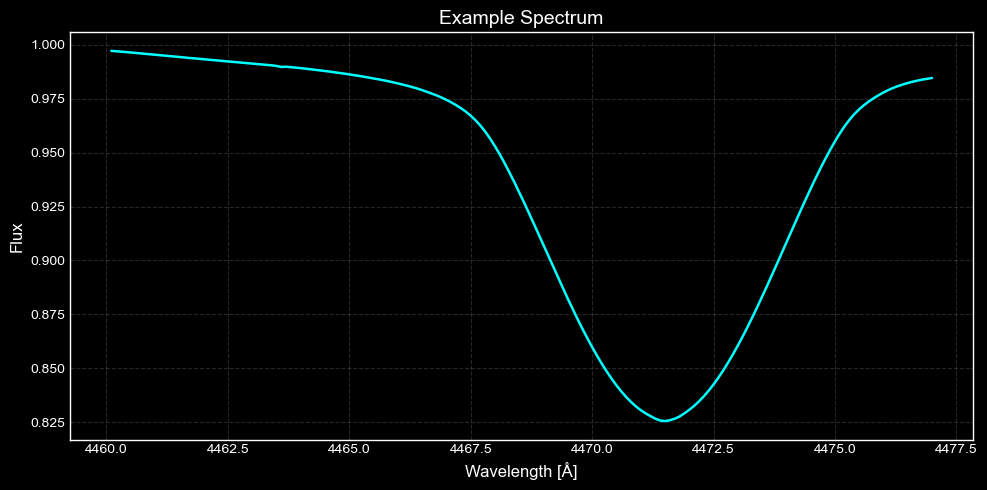

In [23]:
plot_spectrum(wavelengths, X.iloc[2, :], title="Example Spectrum")

#### Training, validation and test separation
To properly evaluate a model its common to separate the data in three sets
* Training data: Data used by the model to learn a task
* Validation data: Data used during training to evaluate generalization or used for model optimization
* Testing data: Data which the model have never seen


In [24]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state=0)

In [25]:
#Lets see the resulting dimensions for each matrix
print("X_train shape: ", X_train.shape)
print("X_val shape: ", X_val.shape)
print("X_test shape: ", X_test.shape)

print("\ny_train shape: ", y_train.shape)
print("y_val shape: ", y_val.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (6841, 170)
X_val shape:  (1711, 170)
X_test shape:  (2139, 170)

y_train shape:  (6841, 2)
y_val shape:  (1711, 2)
y_test shape:  (2139, 2)


## 3. Model Training
---
To predict `Teff` and `vsini` we will use `Random Forest`


#### Random Forest

It consists in an ensamble of decision trees where the final prediction consists in the average of the trees estimation. Each tree is trained with a random subset of the training data and a random set of features (columns) to make different trees.

The idea is that each tree can take independent decisions, so each tree can contribute with what it learned.

![Diagram: Random Forest](Figures/Random_forest_diagram.png)


Some hyperparameters that may affect the performance :
* `n_estimators`:     Number of trees in the forest
* `max_depth`:        Maximum depth of the trees   
* `max_features`:     Maximum amount of features a tree can select

[Random forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

Training model...
Evaluating model...
T_eff – Random forest
  MSE: 13455.05
  MAE: 65.44
  R²:  0.999

v sin i – Random forest
  MSE: 29.22
  MAE: 3.51
  R²:  0.996



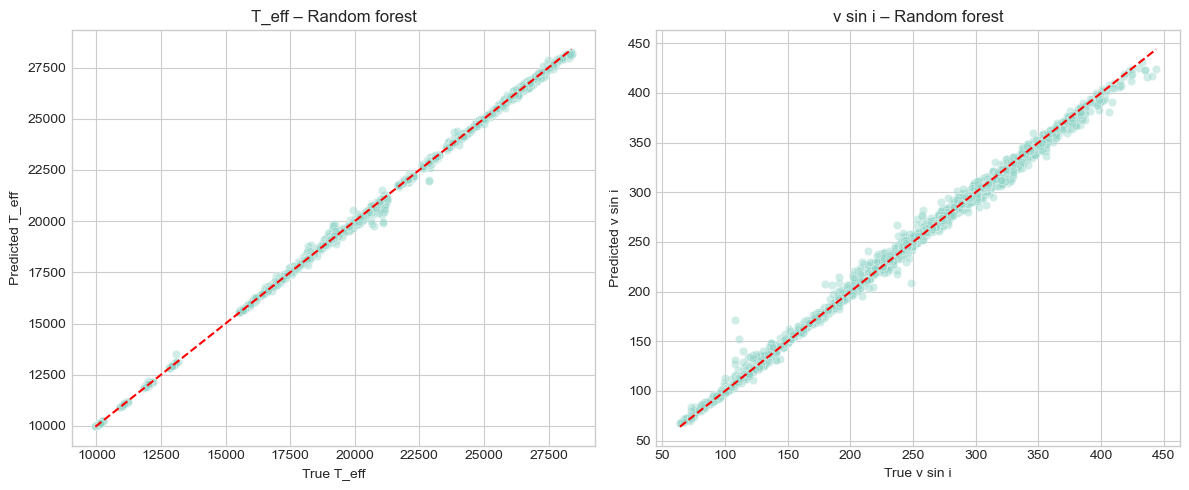

In [26]:
#1. Define the model with default hyperparameters
model_rf  = RandomForestRegressor()

#2. Train using training data
print("Training model...")
model_rf.fit(X_train, y_train)

#3. Evaluate the model using test data
print("Evaluating model...")
y_pred_rf = model_rf.predict(X_test)
plot_results(y_test, y_pred_rf, model_name="Random forest")

## 3. Model optimization

Each model has its own parameters which can be optimized to improve performance.

`GridSearchCV` is method that allows to find the best parameters from a set of posibilities.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)


#### Random forest optimization

Fitting grid...
Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best parameters:  {'max_depth': None, 'max_features': 'log2', 'n_estimators': 50}
Evaluating optimized model...
T_eff – Optimized Random Forest
  MSE: 17664.82
  MAE: 75.06
  R²:  0.999

v sin i – Optimized Random Forest
  MSE: 15.89
  MAE: 2.76
  R²:  0.998



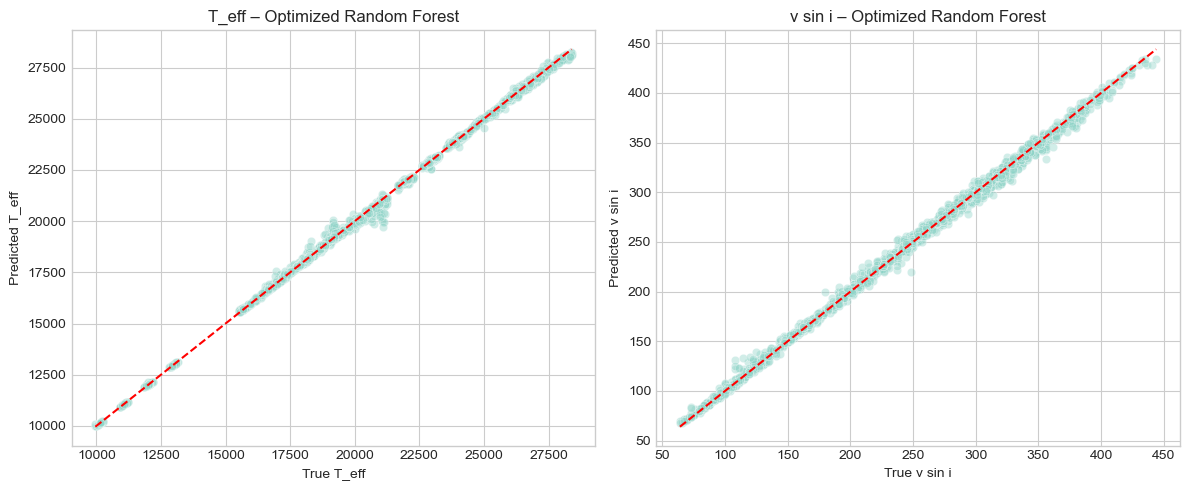

In [33]:
#1. Define a base model
base_model = RandomForestRegressor()

#2. Define the parameter grid and possible values for each one.
param_grid = {
    'n_estimators': [10, 25, 50],        
    'max_depth': [None, 5, 10],       
    'max_features': [1.0, 0.3, 'log2'],          
}

# 3. Configurar GridSearchCV
grid_search = GridSearchCV(
    estimator=base_model, 
    param_grid=param_grid, 
    cv=5,      # cross validation
    n_jobs=-1, # use all processors     
    verbose=1  # show progress
)

#4. Train using training data
print("Fitting grid...")
grid_search.fit(X_train, y_train)

#5. Obtain the best model
best_model_rf = grid_search.best_estimator_
print("Best parameters: ", grid_search.best_params_)

#6. Evaluate the model
print("Evaluating optimized model...")
y_pred_rf_opt = best_model_rf.predict(X_test)
plot_results(y_test, y_pred_rf_opt, "Optimized Random Forest")

To further improve the model a bigger grid may be tested!

*Note: The default value of 100 for `n_estimators` was omitted from the parameter grid to optimize training time.*

## 4. Observed lines

Lets test our models using observed lines
***
| Star | Teff | log g | v sin i |
|---|---|---|---|
| HD 60606 | 19095 ± 656 | 3.94 ± 0.07 | 298 ± 13 |
| HD 212076 | 17374 ± 631 | 3.86 ± 0.15 | 112 ± 8 |
| HD 158427 | 18668 ± 1395 | 4.31 ± 0.15 | 328 ± 15 |
| HD 68980 | 18104 ± 1618 | 3.32 ± 0.33 | 161 ± 13 |

#### Data download

In [34]:
#Check if you are running in Google Colab

if IN_COLAB:
    #Download HD60606 using gdown
    !gdown https://drive.google.com/uc?id=1WGq1GXOD3SnI985wgMnV7u2NyV3l2BQc

    #Read the data in the file downloaded
    df=pd.read_csv("hd60606_4460_4478.dat", header=None,sep=" ")

    #Other stars available if you want to test
    #!gdown https://drive.google.com/uc?id=1codpDGdi9Z-JjzsJqhu0mxQDCY22XNm5
    #!gdown https://drive.google.com/uc?id=1KQ0mYeRgD_A9u0QyjCMAh1YjakyaE23K
    #!gdown https://drive.google.com/uc?id=1-08NwTp8fFFgCeUj8x9qmg9sfSorZyqt

else:
    #seach file in local distk
    file_path = "Data/ML/observed/hd60606_4460_4478.dat"
    if os.path.exists(file_path):
        print("File loaded:", file_path)
        df = pd.read_csv(file_path, header=None, sep=" ")

    else:
        print("File not found. Please download it or check the file path.")

File loaded: Data/ML/observed/hd60606_4460_4478.dat


#### Pre processing

We need the observed data to have the same shape as the data the models were trained on.

**Expected shape**: (n_spectra, dimension)

In [35]:
df.head()


,0,1
0,4460.1,0.993958
1,4460.2,0.978906
2,4460.3,0.989185
3,4460.4,0.997934
4,4460.5,1.009590


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       170 non-null    float64
 1   1       170 non-null    float64
dtypes: float64(2)
memory usage: 2.8 KB


In [37]:
#Lets rename the columns for more clarity 
df.rename(columns={0: 'wavelength', 1:'flux'}, inplace=True)
df.columns

Index(['wavelength', 'flux'], dtype='object')

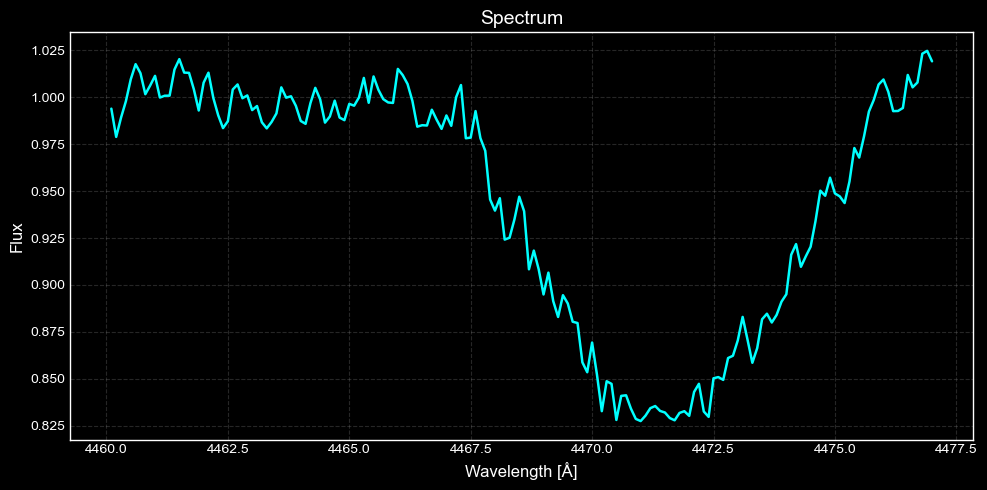

In [38]:
plot_spectrum(df['wavelength'], df['flux'])

In [39]:
X_observed = df["flux"].values.reshape(1, -1)
y_obs_real = [[19095, 298]]


#### Prediction in observed


In [45]:
#Test with linear regression
y_obs_pred_rf = model_rf.predict(X_observed)

print("Random Forest:")
print("Teff:", y_obs_pred_rf[0][0])
print("vsini:", y_obs_pred_rf[0][1])

Random Forest:
Teff: 15755.89
vsini: 110.35


/opt/anaconda3/envs/keras_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [46]:
y_obs_pred_rf_opt = best_model_rf.predict(X_observed)

print("Optimized random forest:")
print("Teff:", y_obs_pred_rf_opt[0][0])
print("vsini:", y_obs_pred_rf_opt[0][1])

Optimized random forest:
Teff: 16727.36
vsini: 156.56


/opt/anaconda3/envs/keras_env/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
